<a href="https://colab.research.google.com/github/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/blob/main/Jobsheet%20Dataset%20PBL/JS09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JOBSHEET 09: KLASIFIKASI I (k-NEAREST NEIGHBORS & NAIVE BAYES)
### Klasifikasi Kelas Harga Properti Multi-Kota Indonesia Menggunakan k-NN (Seleksi Fitur ANOVA & Tuning K) Serta Komparasi Multi-Varian Naive Bayes (Gaussian, Yeo-Johnson, & Multinomial) Berbasis Dataset PBL RumahPoint
**Mata Kuliah:** Pembelajaran Mesin — Semester 5 (Tahun Akademik 2025/2026)  
**Mahasiswa:** Wahyudi Satriawan Hamid  
**NIM / Kelas:** 244107020137 / TI-3H  
**Program Studi:** D-IV Teknik Informatika — Jurusan Teknologi Informasi — Politeknik Negeri Malang  

---

## Bagian 1 — Pemuatan Data, Splitting Anti-Leakage, & Rekayasa Fitur Terkurasi


In [1]:
# ==============================================================================
# BAGIAN 1.1: IMPORT LIBRARY, KONFIGURASI, & LOADER DATA DUAL-MODE
# ==============================================================================
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    PowerTransformer,
    OneHotEncoder,
    label_binarize
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 100

print("=" * 80)
print("SISTEM INFORMASI LINGKUNGAN KOMPUTASI (GOOGLE COLAB / LOCAL JUPYTER)")
print("=" * 80)
print(f"Versi Python        : {sys.version.split()[0]}")
print(f"Versi NumPy         : {np.__version__}")
print(f"Versi Pandas        : {pd.__version__}")
import sklearn
print(f"Versi Scikit-Learn  : {sklearn.__version__}")

# Pemuatan data cerdas dual-mode
DATASET_FILENAME = "properti_multi_kota_clean.csv"
LOCAL_PATH = os.path.join("..", "Dataset", DATASET_FILENAME)
GITHUB_RAW_URL = f"https://raw.githubusercontent.com/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/main/Dataset/{DATASET_FILENAME}"

if os.path.exists(LOCAL_PATH):
    print(f"[LOADER] Memuat dataset dari penyimpanan lokal: {LOCAL_PATH}")
    df = pd.read_csv(LOCAL_PATH)
else:
    print(f"[LOADER] Path lokal tidak ditemukan. Mengunduh langsung dari GitHub RAW: {GITHUB_RAW_URL}")
    df = pd.read_csv(GITHUB_RAW_URL)

print(f"[LOADER] Berhasil memuat data: {df.shape[0]:,} baris, {df.shape[1]} kolom.")
print("=" * 80)
df.head()

SISTEM INFORMASI LINGKUNGAN KOMPUTASI (GOOGLE COLAB / LOCAL JUPYTER)
Versi Python        : 3.13.18
Versi NumPy         : 2.4.6
Versi Pandas        : 2.2.3
Versi Scikit-Learn  : 1.6.1
[LOADER] Path lokal tidak ditemukan. Mengunduh langsung dari GitHub RAW: https://raw.githubusercontent.com/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/main/Dataset/properti_multi_kota_clean.csv
[LOADER] Berhasil memuat data: 56,170 baris, 12 kolom.


,sumber,lokasi,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga,kondisi,lokasi_bersih,kelas_harga,kelas_harga_biner
0,uas-properti/Jabodetabek,Tangerang,30.0,NaN,3.0,3.0,33.0,2.037543e+08,Bekas,Tangerang,Murah,Murah
1,uas-properti/Jabodetabek,Bekasi,122.0,NaN,5.0,4.0,19.0,1.058032e+09,Bekas,Bekasi,Sedang,Mahal
2,uas-properti/Jabodetabek,Bekasi,142.8,NaN,1.0,1.0,9.0,1.335793e+09,Bekas,Bekasi,Mahal,Mahal
3,uas-properti/Jabodetabek,Bekasi,152.6,NaN,4.0,3.0,6.0,1.613771e+09,Bekas,Bekasi,Mahal,Mahal
4,uas-properti/Jabodetabek,Depok,61.2,NaN,1.0,1.0,9.0,5.221562e+08,Bekas,Depok,Sedang,Murah


In [2]:
# ==============================================================================
# BAGIAN 1.2: REKAYASA FITUR DOMAIN PROPERTI & SPLITTING ANTI-LEAKAGE
# ==============================================================================
# 1. Rekayasa Fitur Domain Terkurasi (Konsisten JS03, Menghindari Multikolinearitas total_ruangan)
df_model = df.copy()

# Fitur 1: Indikator Properti Komersial (0 kamar)
df_model['is_komersil'] = (df_model['jumlah_kamar'] == 0).astype(int)

# Fitur 2: Rasio Luas Bangunan terhadap Luas Tanah (Building-to-Land Ratio)
df_model['rasio_bangunan_tanah'] = df_model['luas_bangunan'] / df_model['luas_m2']

# Fitur 3: Rasio Kamar Mandi per Kamar Tidur (Luxury Ratio)
df_model['rasio_km_kt'] = df_model['jumlah_kamar_mandi'] / (df_model['jumlah_kamar'] + 1)

# Fitur 4: Luas Bangunan per Kamar (Spaciousness Metric)
df_model['luas_per_kamar'] = df_model['luas_bangunan'] / (df_model['jumlah_kamar'] + 1)

print(f"[FEATURE ENGINEERING] 4 Fitur domain berhasil dibuat.")
print(f"Catatan: 'total_ruangan' dieksklusi karena multikolinearitas linier sempurna (VIF > 10).")

# 2. Pemisahan Matriks Fitur dan Target (Anti Target-Leakage)
cols_drop_leakage = ['harga', 'kelas_harga_biner', 'sumber', 'lokasi', 'usia_bangunan', 'kelas_harga']
X_raw = df_model.drop(columns=cols_drop_leakage).copy()
y = df_model['kelas_harga'].copy()

# 3. Stratified Train-Test Split (80% Train / 20% Test)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, stratify=y, random_state=42
)

# 4. Reduksi Kardinalitas Top-15 Lokasi Eksklusif dari X_train_raw
top15_lokasi = X_train_raw['lokasi_bersih'].value_counts().nlargest(15).index.tolist()

X_train = X_train_raw.copy()
X_test = X_test_raw.copy()
X_train['lokasi_top15'] = X_train['lokasi_bersih'].apply(lambda x: x if x in top15_lokasi else 'Lainnya')
X_test['lokasi_top15'] = X_test['lokasi_bersih'].apply(lambda x: x if x in top15_lokasi else 'Lainnya')

print("\n" + "=" * 80)
print("DISTRIBUSI KELAS TARGET PADA DATA LATIH DAN DATA UJI")
print("=" * 80)
df_dist_train = y_train.value_counts(normalize=True).mul(100).rename("Train (%)")
df_dist_test = y_test.value_counts(normalize=True).mul(100).rename("Test (%)")
df_dist_count = y_train.value_counts().rename("Train (Jml)")
display(pd.concat([df_dist_count, df_dist_train, df_dist_test], axis=1))

print(f"Ukuran Data Latih (X_train): {X_train.shape[0]:,} baris")
print(f"Ukuran Data Uji   (X_test) : {X_test.shape[0]:,} baris")

[FEATURE ENGINEERING] 4 Fitur domain berhasil dibuat.
Catatan: 'total_ruangan' dieksklusi karena multikolinearitas linier sempurna (VIF > 10).

DISTRIBUSI KELAS TARGET PADA DATA LATIH DAN DATA UJI


,Train (Jml),Train (%),Test (%)
kelas_harga,,,
Sedang,14982,33.340751,33.336301
Murah,14978,33.331850,33.336301
Mahal,14976,33.327399,33.327399


Ukuran Data Latih (X_train): 44,936 baris
Ukuran Data Uji   (X_test) : 11,234 baris


## Bagian 2 — k-Nearest Neighbors (k-NN): Seleksi Fitur Optimal & Tuning K (Adaptasi Praktikum 1 & Tugas 1)

15 FITUR DENGAN SKOR ANOVA F-VALUE TERTINGGI PADA TARGET KELAS HARGA


,Fitur,F_Score,P_Value
0,jumlah_kamar_mandi,2531.555161,0.000000e+00
1,luas_bangunan,1585.986924,0.000000e+00
2,jumlah_kamar,1243.668760,0.000000e+00
3,rasio_km_kt,824.696350,0.000000e+00
4,luas_m2,810.933523,0.000000e+00
5,luas_per_kamar,651.319958,1.274185e-266
6,lokasi_top15_Lainnya,173.090842,1.258549e-74
7,rasio_bangunan_tanah,155.186288,4.251138e-67
8,lokasi_top15_Tangerang Selatan,110.747563,2.679327e-48
9,kondisi_Bekas,104.623303,1.075640e-45


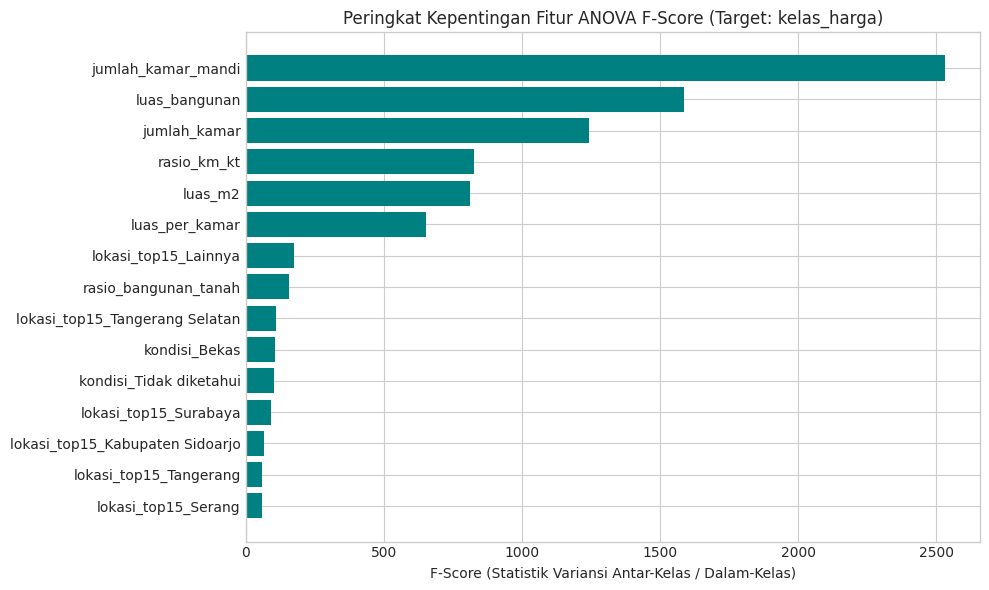

In [3]:
# ==============================================================================
# BAGIAN 2.1: PREPROCESSOR PIPELINE & PEMERINGKATAN FITUR ANOVA F-SCORE
# ==============================================================================
# Definisi kelompok fitur
fitur_numerik = [
    'luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi',
    'is_komersil', 'rasio_bangunan_tanah', 'rasio_km_kt', 'luas_per_kamar'
]
fitur_kategorikal = ['lokasi_top15', 'kondisi']

# ColumnTransformer pra-pemrosesan terintegrasi
preprocessor_knn = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), fitur_numerik),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), fitur_kategorikal)
    ]
)

# 1. Ambil Subsampel 10.000 baris terstratifikasi dari X_train untuk eksplorasi cepat
X_sub_train, _, y_sub_train, _ = train_test_split(
    X_train[fitur_numerik + fitur_kategorikal], y_train, train_size=10000, stratify=y_train, random_state=42
)

# 2. Fit Preprocessor pada subsampel dan ekstrak nama fitur yang di-encode
X_sub_proc = preprocessor_knn.fit_transform(X_sub_train)
cat_ohe = preprocessor_knn.named_transformers_['cat'].named_steps['ohe']
cat_encoded_names = cat_ohe.get_feature_names_out(fitur_kategorikal).tolist()
all_feature_names = fitur_numerik + cat_encoded_names

# 3. Hitung Skor ANOVA F-Value (f_classif)
selector_anova = SelectKBest(score_func=f_classif, k='all')
selector_anova.fit(X_sub_proc, y_sub_train)

df_anova = pd.DataFrame({
    'Fitur': all_feature_names,
    'F_Score': selector_anova.scores_,
    'P_Value': selector_anova.pvalues_
}).sort_values(by='F_Score', ascending=False).reset_index(drop=True)

print("=" * 80)
print("15 FITUR DENGAN SKOR ANOVA F-VALUE TERTINGGI PADA TARGET KELAS HARGA")
print("=" * 80)
display(df_anova.head(15))

# Visualisasi Bar Chart Peringkat Fitur ANOVA
top15_anova = df_anova.head(15).sort_values(by='F_Score', ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top15_anova['Fitur'], top15_anova['F_Score'], color='teal')
ax.set_title("Peringkat Kepentingan Fitur ANOVA F-Score (Target: kelas_harga)")
ax.set_xlabel("F-Score (Statistik Variansi Antar-Kelas / Dalam-Kelas)")
plt.tight_layout()
plt.show()

In [4]:
# ==============================================================================
# BAGIAN 2.2: EKSPERIMEN SUBSET JUMLAH FITUR OPTIMAL (5-FOLD STRATIFIED CV)
# ==============================================================================
# Menguji jumlah subset fitur: Top-5, Top-10, Top-15, dan Semua Fitur
k_subsets = [5, 10, 15, len(all_feature_names)]
label_subsets = ['Top-5 Fitur', 'Top-10 Fitur', 'Top-15 Fitur', 'Semua Fitur']

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
hasil_subset = []

print("Mengevaluasi subset fitur terbaik dengan k-NN (K=11, weights='distance') pada 10.000 subsampel...")
for k_val, label in zip(k_subsets, label_subsets):
    t0 = time.time()
    selector = SelectKBest(score_func=f_classif, k=k_val)
    X_sub_selected = selector.fit_transform(X_sub_proc, y_sub_train)

    knn_exp = KNeighborsClassifier(n_neighbors=11, weights='distance')
    scores_acc = cross_val_score(knn_exp, X_sub_selected, y_sub_train, cv=cv_strat, scoring='accuracy')
    scores_f1 = cross_val_score(knn_exp, X_sub_selected, y_sub_train, cv=cv_strat, scoring='f1_macro')
    t_elapsed = time.time() - t0

    hasil_subset.append({
        'Subset Fitur': label,
        'Jumlah Fitur': k_val,
        'Mean CV Akurasi': scores_acc.mean(),
        'Std CV Akurasi': scores_acc.std(),
        'Mean CV Macro F1': scores_f1.mean(),
        'Std CV Macro F1': scores_f1.std(),
        'Waktu CV (s)': t_elapsed
    })

df_hasil_subset = pd.DataFrame(hasil_subset)
print("=" * 85)
print("TABEL KOMPARASI SUBSET FITUR HASIL ANOVA TERHADAP PERFORMA k-NN (5-Fold CV)")
print("=" * 85)
display(df_hasil_subset.style.format({
    'Mean CV Akurasi': '{:.4f}', 'Std CV Akurasi': '{:.4f}',
    'Mean CV Macro F1': '{:.4f}', 'Std CV Macro F1': '{:.4f}',
    'Waktu CV (s)': '{:.2f}'
}))

# Tentukan subset terbaik berdasarkan Macro F1
idx_best = df_hasil_subset['Mean CV Macro F1'].idxmax()
best_k_features = df_hasil_subset.loc[idx_best, 'Jumlah Fitur']
best_subset_label = df_hasil_subset.loc[idx_best, 'Subset Fitur']
print(f"[REKOMENDASI FITUR TUGAS 1] Konfigurasi Fitur Terbaik: {best_subset_label} ({best_k_features} fitur).")

Mengevaluasi subset fitur terbaik dengan k-NN (K=11, weights='distance') pada 10.000 subsampel...
TABEL KOMPARASI SUBSET FITUR HASIL ANOVA TERHADAP PERFORMA k-NN (5-Fold CV)


,Subset Fitur,Jumlah Fitur,Mean CV Akurasi,Std CV Akurasi,Mean CV Macro F1,Std CV Macro F1,Waktu CV (s)
0,Top-5 Fitur,5,0.6637,0.0171,0.6592,0.0166,0.99
1,Top-10 Fitur,10,0.7044,0.0118,0.7022,0.0118,2.19
2,Top-15 Fitur,15,0.7123,0.0105,0.7103,0.0103,4.04
3,Semua Fitur,27,0.7222,0.0079,0.7205,0.0078,1.92


[REKOMENDASI FITUR TUGAS 1] Konfigurasi Fitur Terbaik: Semua Fitur (27 fitur).


Melakukan grid sweep nilai K ganjil (1 s/d 31) untuk bobot 'uniform' vs 'distance'...


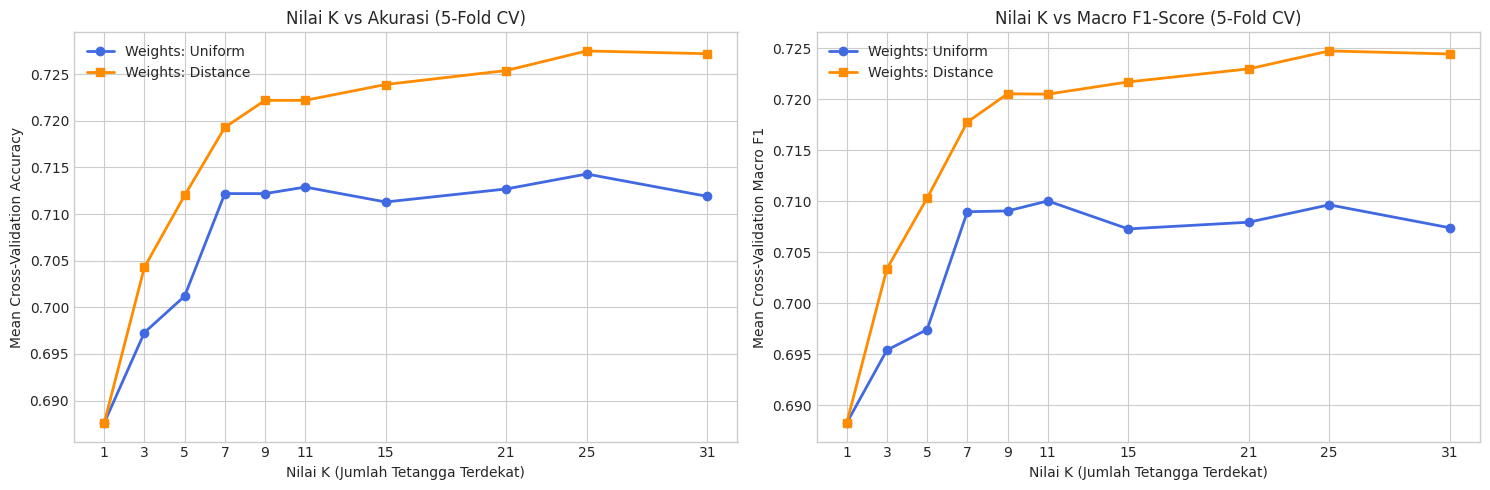

[OPTIMASI SELESAI] Nilai K Terbaik: 25 | Bobot: 'distance' | Estimasi CV Macro F1: 0.7247


In [5]:
# ==============================================================================
# BAGIAN 2.3: TUNING NILAI K GANJIL & PERBANDINGAN BOBOT (UNIFORM VS DISTANCE)
# ==============================================================================
# Menerapkan seleksi fitur terbaik pada data subsampel
selector_best = SelectKBest(score_func=f_classif, k=best_k_features)
X_sub_opt = selector_best.fit_transform(X_sub_proc, y_sub_train)

# Daftar nilai K ganjil untuk menghindari voting seri
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 25, 31]

cv_acc_uniform, cv_f1_uniform = [], []
cv_acc_distance, cv_f1_distance = [], []

print("Melakukan grid sweep nilai K ganjil (1 s/d 31) untuk bobot 'uniform' vs 'distance'...")
for k in k_values:
    # Model dengan bobot Uniform
    knn_u = KNeighborsClassifier(n_neighbors=k, weights='uniform')
    acc_u = cross_val_score(knn_u, X_sub_opt, y_sub_train, cv=cv_strat, scoring='accuracy').mean()
    f1_u = cross_val_score(knn_u, X_sub_opt, y_sub_train, cv=cv_strat, scoring='f1_macro').mean()
    cv_acc_uniform.append(acc_u)
    cv_f1_uniform.append(f1_u)

    # Model dengan bobot Distance
    knn_d = KNeighborsClassifier(n_neighbors=k, weights='distance')
    acc_d = cross_val_score(knn_d, X_sub_opt, y_sub_train, cv=cv_strat, scoring='accuracy').mean()
    f1_d = cross_val_score(knn_d, X_sub_opt, y_sub_train, cv=cv_strat, scoring='f1_macro').mean()
    cv_acc_distance.append(acc_d)
    cv_f1_distance.append(f1_d)

# Visualisasi Kurva Tuning K vs Metrik Evaluasi
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot Akurasi vs K
axes[0].plot(k_values, cv_acc_uniform, marker='o', linewidth=2, color='royalblue', label='Weights: Uniform')
axes[0].plot(k_values, cv_acc_distance, marker='s', linewidth=2, color='darkorange', label='Weights: Distance')
axes[0].set_title("Nilai K vs Akurasi (5-Fold CV)")
axes[0].set_xlabel("Nilai K (Jumlah Tetangga Terdekat)")
axes[0].set_ylabel("Mean Cross-Validation Accuracy")
axes[0].set_xticks(k_values)
axes[0].legend()

# Plot Macro F1 vs K
axes[1].plot(k_values, cv_f1_uniform, marker='o', linewidth=2, color='royalblue', label='Weights: Uniform')
axes[1].plot(k_values, cv_f1_distance, marker='s', linewidth=2, color='darkorange', label='Weights: Distance')
axes[1].set_title("Nilai K vs Macro F1-Score (5-Fold CV)")
axes[1].set_xlabel("Nilai K (Jumlah Tetangga Terdekat)")
axes[1].set_ylabel("Mean Cross-Validation Macro F1")
axes[1].set_xticks(k_values)
axes[1].legend()

plt.tight_layout()
plt.show()

# Menentukan K dan bobot optimal
best_idx_d = np.argmax(cv_f1_distance)
best_idx_u = np.argmax(cv_f1_uniform)

if cv_f1_distance[best_idx_d] >= cv_f1_uniform[best_idx_u]:
    best_k = k_values[best_idx_d]
    best_weight = 'distance'
    best_cv_f1 = cv_f1_distance[best_idx_d]
else:
    best_k = k_values[best_idx_u]
    best_weight = 'uniform'
    best_cv_f1 = cv_f1_uniform[best_idx_u]

print(f"[OPTIMASI SELESAI] Nilai K Terbaik: {best_k} | Bobot: '{best_weight}' | Estimasi CV Macro F1: {best_cv_f1:.4f}")

Melatih model k-NN final pada seluruh 44.936 baris X_train...
Melakukan inferensi pada 11.234 baris X_test...
HASIL EVALUASI MODEL k-NN FINAL PADA DATA UJI (11.234 Baris)
Waktu Pelatihan (Train Time)   : 0.239 detik
Waktu Inferensi (Inference)    : 8.748 detik (0.779 ms / sampel)
Akurasi Pengujian (Accuracy)   : 75.63%
Macro Precision                : 0.7533
Macro Recall                   : 0.7563
Macro F1-Score                 : 0.7541
Macro ROC-AUC (OvR)            : 0.3117

Laporan Klasifikasi Terperinci:
              precision    recall  f1-score   support

       Mahal     0.8133    0.8272    0.8202      3744
       Murah     0.7734    0.8246    0.7981      3745
      Sedang     0.6732    0.6171    0.6439      3745

    accuracy                         0.7563     11234
   macro avg     0.7533    0.7563    0.7541     11234
weighted avg     0.7533    0.7563    0.7541     11234



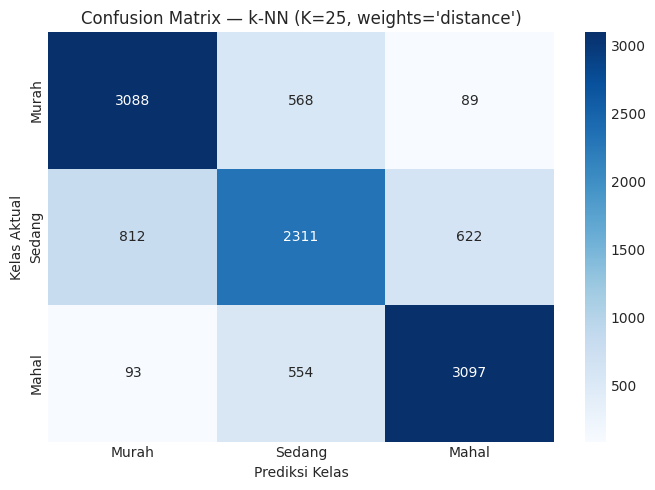

In [6]:
# ==============================================================================
# BAGIAN 2.4: PELATIHAN MODEL k-NN FINAL (44.936 TRAIN) & EVALUASI TEST SET
# ==============================================================================
# Konstruksi Pipeline k-NN Final Terpadu
pipeline_knn_final = Pipeline([
    ('preprocessor', preprocessor_knn),
    ('selector', SelectKBest(score_func=f_classif, k=best_k_features)),
    ('classifier', KNeighborsClassifier(n_neighbors=best_k, weights=best_weight))
])

# Pelatihan model k-NN final pada SELURUH 44.936 baris data latih
print(f"Melatih model k-NN final pada seluruh 44.936 baris X_train...")
t0 = time.time()
pipeline_knn_final.fit(X_train[fitur_numerik + fitur_kategorikal], y_train)
t_fit_knn = time.time() - t0

# Pengujian inferensi pada 11.234 baris data uji murni
print(f"Melakukan inferensi pada 11.234 baris X_test...")
t0 = time.time()
y_pred_knn = pipeline_knn_final.predict(X_test[fitur_numerik + fitur_kategorikal])
y_prob_knn = pipeline_knn_final.predict_proba(X_test[fitur_numerik + fitur_kategorikal])
t_pred_knn = time.time() - t0

# Perhitungan metrik evaluasi
classes_order = ['Murah', 'Sedang', 'Mahal']
y_test_bin = label_binarize(y_test, classes=classes_order)

acc_knn = accuracy_score(y_test, y_pred_knn)
prec_knn = precision_score(y_test, y_pred_knn, average='macro')
rec_knn = recall_score(y_test, y_pred_knn, average='macro')
f1_knn = f1_score(y_test, y_pred_knn, average='macro')
auc_knn = roc_auc_score(y_test_bin, y_prob_knn, multi_class='ovr', average='macro')

print("=" * 80)
print(f"HASIL EVALUASI MODEL k-NN FINAL PADA DATA UJI (11.234 Baris)")
print("=" * 80)
print(f"Waktu Pelatihan (Train Time)   : {t_fit_knn:.3f} detik")
print(f"Waktu Inferensi (Inference)    : {t_pred_knn:.3f} detik ({t_pred_knn/len(X_test)*1000:.3f} ms / sampel)")
print(f"Akurasi Pengujian (Accuracy)   : {acc_knn*100:.2f}%")
print(f"Macro Precision                : {prec_knn:.4f}")
print(f"Macro Recall                   : {rec_knn:.4f}")
print(f"Macro F1-Score                 : {f1_knn:.4f}")
print(f"Macro ROC-AUC (OvR)            : {auc_knn:.4f}")
print("\nLaporan Klasifikasi Terperinci:")
print(classification_report(y_test, y_pred_knn, digits=4))

# Visualisasi Confusion Matrix Heatmap
cm_knn = confusion_matrix(y_test, y_pred_knn, labels=classes_order)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues', xticklabels=classes_order, yticklabels=classes_order, ax=ax)
ax.set_title(f"Confusion Matrix — k-NN (K={best_k}, weights='{best_weight}')")
ax.set_xlabel("Prediksi Kelas")
ax.set_ylabel("Kelas Aktual")
plt.tight_layout()
plt.show()

## Bagian 3 — Klasifikasi Naive Bayes Multi-Varian (Adaptasi Praktikum 2, 3, & Tugas 2)

Pada bagian ini, kita mengadaptasikan Praktikum 2, Praktikum 3, dan Tugas 2 modul Naive Bayes ke dalam konteks data tabular properti multi-kota.

In [7]:
# ==============================================================================
# BAGIAN 3.1: PELATIHAN & KOMPARASI 3 VARIAN NAIVE BAYES PADA DATA PENUH
# ==============================================================================
# 1. Pipeline Varian 1: GaussianNB Baseline (StandardScaler)
pipe_gnb_baseline = Pipeline([
    ('preprocessor', ColumnTransformer([
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), fitur_numerik),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), fitur_kategorikal)
    ])),
    ('classifier', GaussianNB())
])

# 2. Pipeline Varian 2: GaussianNB + PowerTransformer Yeo-Johnson (Normalisasi Distribusi)
pipe_gnb_yeojohnson = Pipeline([
    ('preprocessor', ColumnTransformer([
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('pt', PowerTransformer(method='yeo-johnson'))
        ]), fitur_numerik),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), fitur_kategorikal)
    ])),
    ('classifier', GaussianNB())
])

# 3. Pipeline Varian 3: MultinomialNB (MinMaxScaler Non-Negatif [0, 1])
pipe_mnb_tabular = Pipeline([
    ('preprocessor', ColumnTransformer([
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', MinMaxScaler())
        ]), fitur_numerik),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), fitur_kategorikal)
    ])),
    ('classifier', MultinomialNB())
])

daftar_nb_models = [
    ('GaussianNB (Baseline StandardScaler)', pipe_gnb_baseline),
    ('GaussianNB + PowerTransformer (Yeo-Johnson)', pipe_gnb_yeojohnson),
    ('MultinomialNB (MinMaxScaler)', pipe_mnb_tabular)
]

hasil_nb = []
nb_predictions = {}
nb_probabilities = {}

X_train_input = X_train[fitur_numerik + fitur_kategorikal]
X_test_input = X_test[fitur_numerik + fitur_kategorikal]

for nama_model, pipe in daftar_nb_models:
    print(f"Melatih model {nama_model}...")
    t0 = time.time()
    pipe.fit(X_train_input, y_train)
    t_fit = time.time() - t0

    t0 = time.time()
    y_pred = pipe.predict(X_test_input)
    y_prob = pipe.predict_proba(X_test_input)
    t_pred = time.time() - t0

    nb_predictions[nama_model] = y_pred
    nb_probabilities[nama_model] = y_prob

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='macro')
    rec = recall_score(y_test, y_pred, average='macro')
    f1 = f1_score(y_test, y_pred, average='macro')
    auc = roc_auc_score(y_test_bin, y_prob, multi_class='ovr', average='macro')

    hasil_nb.append({
        'Model Naive Bayes': nama_model,
        'Waktu Latih (s)': t_fit,
        'Waktu Inferensi (s)': t_pred,
        'Akurasi (%)': acc * 100,
        'Macro Precision': prec,
        'Macro Recall': rec,
        'Macro F1': f1,
        'Macro ROC-AUC': auc
    })

df_hasil_nb = pd.DataFrame(hasil_nb)
print("=" * 95)
print("TABEL KOMPARASI 3 VARIAN NAIVE BAYES PADA TEST SET (11.234 Baris)")
print("=" * 95)
display(df_hasil_nb.style.format({
    'Waktu Latih (s)': '{:.3f}', 'Waktu Inferensi (s)': '{:.3f}',
    'Akurasi (%)': '{:.2f}%', 'Macro Precision': '{:.4f}',
    'Macro Recall': '{:.4f}', 'Macro F1': '{:.4f}', 'Macro ROC-AUC': '{:.4f}'
}))

Melatih model GaussianNB (Baseline StandardScaler)...
Melatih model GaussianNB + PowerTransformer (Yeo-Johnson)...
Melatih model MultinomialNB (MinMaxScaler)...
TABEL KOMPARASI 3 VARIAN NAIVE BAYES PADA TEST SET (11.234 Baris)


,Model Naive Bayes,Waktu Latih (s),Waktu Inferensi (s),Akurasi (%),Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC
0,GaussianNB (Baseline StandardScaler),0.174,0.055,58.01%,0.5754,0.5801,0.5539,0.4164
1,GaussianNB + PowerTransformer (Yeo-Johnson),0.531,0.061,61.32%,0.6033,0.6132,0.5709,0.3924
2,MultinomialNB (MinMaxScaler),0.204,0.064,50.85%,0.5270,0.5085,0.4851,0.3576


[MODEL TERBAIK NAIVE BAYES]: GaussianNB + PowerTransformer (Yeo-Johnson)
Macro F1: 0.5709 | Akurasi: 61.32%

Laporan Klasifikasi Naive Bayes Terbaik:
              precision    recall  f1-score   support

       Mahal     0.6864    0.7722    0.7267      3744
       Murah     0.5742    0.8654    0.6904      3745
      Sedang     0.5493    0.2021    0.2955      3745

    accuracy                         0.6132     11234
   macro avg     0.6033    0.6132    0.5709     11234
weighted avg     0.6033    0.6132    0.5709     11234



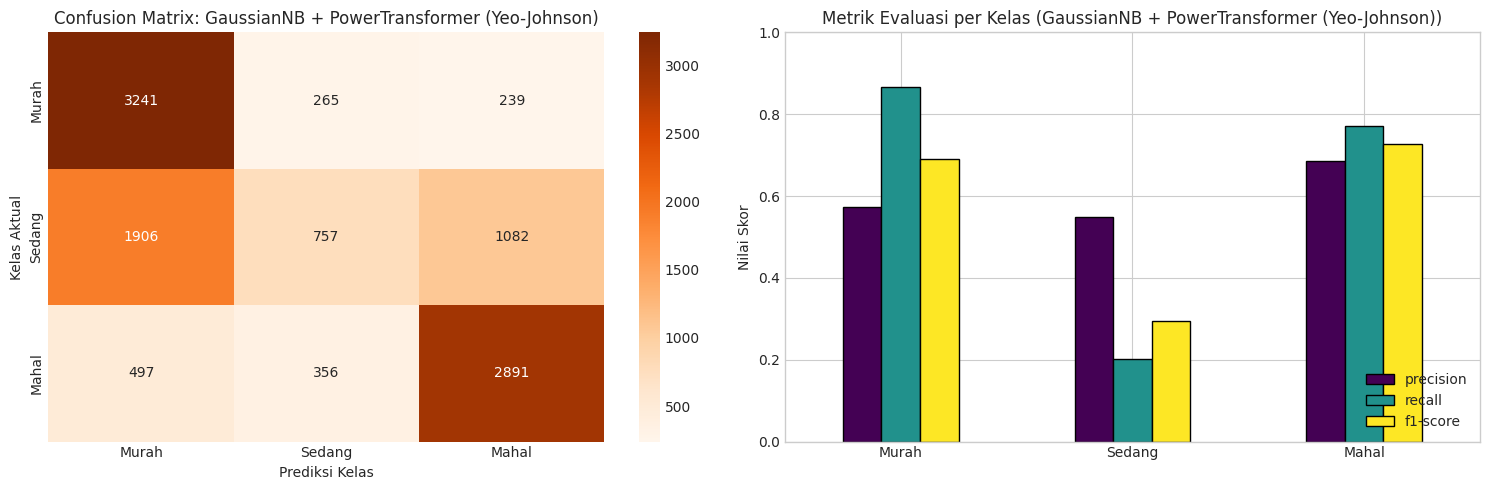

In [8]:
# ==============================================================================
# BAGIAN 3.2: DIAGNOSTIK & CONFUSION MATRIX MODEL NAIVE BAYES TERBAIK
# ==============================================================================
# Ambil model Naive Bayes terbaik berdasarkan Macro F1
idx_best_nb = df_hasil_nb['Macro F1'].idxmax()
best_nb_name = df_hasil_nb.loc[idx_best_nb, 'Model Naive Bayes']
y_pred_best_nb = nb_predictions[best_nb_name]
y_prob_best_nb = nb_probabilities[best_nb_name]

print(f"[MODEL TERBAIK NAIVE BAYES]: {best_nb_name}")
print(f"Macro F1: {df_hasil_nb.loc[idx_best_nb, 'Macro F1']:.4f} | Akurasi: {df_hasil_nb.loc[idx_best_nb, 'Akurasi (%)']:.2f}%")
print("\nLaporan Klasifikasi Naive Bayes Terbaik:")
print(classification_report(y_test, y_pred_best_nb, digits=4))

# Visualisasi Confusion Matrix Heatmap
cm_nb = confusion_matrix(y_test, y_pred_best_nb, labels=classes_order)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Confusion Matrix Heatmap
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Oranges', xticklabels=classes_order, yticklabels=classes_order, ax=axes[0])
axes[0].set_title(f"Confusion Matrix: {best_nb_name}")
axes[0].set_xlabel("Prediksi Kelas")
axes[0].set_ylabel("Kelas Aktual")

# Bar Chart Metrik per Kelas
report_dict = classification_report(y_test, y_pred_best_nb, output_dict=True)
df_class_metrics = pd.DataFrame([report_dict[c] for c in classes_order], index=classes_order)[['precision', 'recall', 'f1-score']]

df_class_metrics.plot(kind='bar', ax=axes[1], colormap='viridis', edgecolor='black')
axes[1].set_title(f"Metrik Evaluasi per Kelas ({best_nb_name})")
axes[1].set_ylabel("Nilai Skor")
axes[1].set_ylim(0, 1.0)
axes[1].legend(loc='lower right')
axes[1].set_xticklabels(classes_order, rotation=0)

plt.tight_layout()
plt.show()

## Bagian 4 — Komparasi Akhir k-NN Optimal vs Naive Bayes Terbaik

Pada bagian ini, kita melakukan evaluasi *head-to-head* antara model **k-NN optimal** dan model **Naive Bayes terbaik** pada 11.234 baris data uji yang identik.

In [9]:
# ==============================================================================
# BAGIAN 4.1: TABEL KOMPARASI HEAD-TO-HEAD (k-NN OPTIMAL VS NAIVE BAYES TERBAIK)
# ==============================================================================
komparasi_final = [
    {
        'Algoritma': f"k-NN Optimal (K={best_k}, {best_weight})",
        'Paradigma': "Instance-Based Non-Parametrik (Lazy)",
        'Akurasi (%)': acc_knn * 100,
        'Macro Precision': prec_knn,
        'Macro Recall': rec_knn,
        'Macro F1': f1_knn,
        'Macro ROC-AUC': auc_knn,
        'Waktu Latih (s)': t_fit_knn,
        'Waktu Inferensi (s)': t_pred_knn,
        'Latensi per 1k Sampel (ms)': (t_pred_knn / len(X_test)) * 1000 * 1000
    },
    {
        'Algoritma': best_nb_name,
        'Paradigma': "Probabilistik Parametrik (Eager)",
        'Akurasi (%)': df_hasil_nb.loc[idx_best_nb, 'Akurasi (%)'],
        'Macro Precision': df_hasil_nb.loc[idx_best_nb, 'Macro Precision'],
        'Macro Recall': df_hasil_nb.loc[idx_best_nb, 'Macro Recall'],
        'Macro F1': df_hasil_nb.loc[idx_best_nb, 'Macro F1'],
        'Macro ROC-AUC': df_hasil_nb.loc[idx_best_nb, 'Macro ROC-AUC'],
        'Waktu Latih (s)': df_hasil_nb.loc[idx_best_nb, 'Waktu Latih (s)'],
        'Waktu Inferensi (s)': df_hasil_nb.loc[idx_best_nb, 'Waktu Inferensi (s)'],
        'Latensi per 1k Sampel (ms)': (df_hasil_nb.loc[idx_best_nb, 'Waktu Inferensi (s)'] / len(X_test)) * 1000 * 1000
    }
]

df_komparasi_final = pd.DataFrame(komparasi_final)
print("=" * 110)
print("TABEL KOMPARASI HEAD-TO-HEAD: k-NN OPTIMAL VS NAIVE BAYES TERBAIK PADA TEST SET (11.234 Baris)")
print("=" * 110)
display(df_komparasi_final.style.format({
    'Akurasi (%)': '{:.2f}%',
    'Macro Precision': '{:.4f}',
    'Macro Recall': '{:.4f}',
    'Macro F1': '{:.4f}',
    'Macro ROC-AUC': '{:.4f}',
    'Waktu Latih (s)': '{:.3f}',
    'Waktu Inferensi (s)': '{:.3f}',
    'Latensi per 1k Sampel (ms)': '{:.2f} ms'
}))

TABEL KOMPARASI HEAD-TO-HEAD: k-NN OPTIMAL VS NAIVE BAYES TERBAIK PADA TEST SET (11.234 Baris)


,Algoritma,Paradigma,Akurasi (%),Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC,Waktu Latih (s),Waktu Inferensi (s),Latensi per 1k Sampel (ms)
0,"k-NN Optimal (K=25, distance)",Instance-Based Non-Parametrik (Lazy),75.63%,0.7533,0.7563,0.7541,0.3117,0.239,8.748,778.71 ms
1,GaussianNB + PowerTransformer (Yeo-Johnson),Probabilistik Parametrik (Eager),61.32%,0.6033,0.6132,0.5709,0.3924,0.531,0.061,5.40 ms


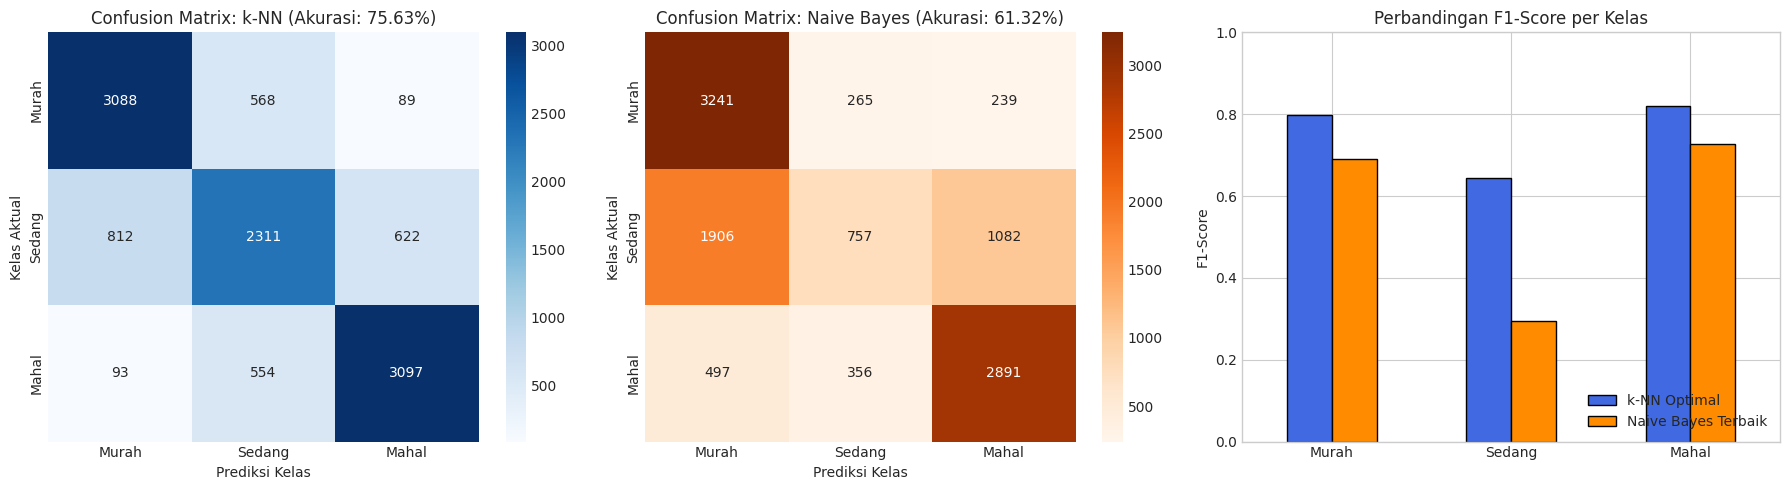

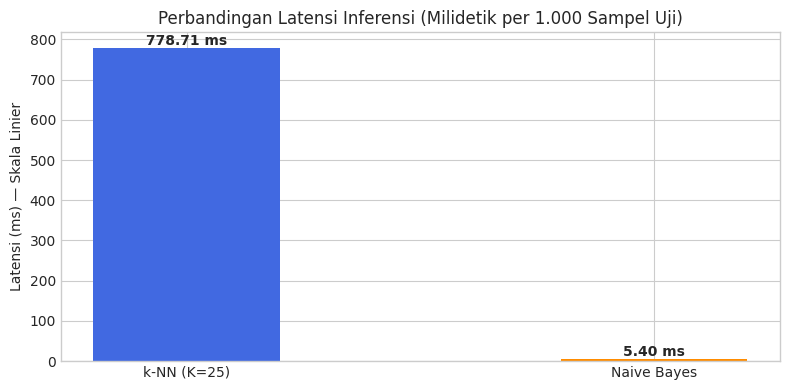

In [10]:
# ==============================================================================
# BAGIAN 4.2: VISUALISASI KOMPARASI BERDAMPINGAN (CONFUSION MATRIX & METRIK PER KELAS)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix k-NN
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues', xticklabels=classes_order, yticklabels=classes_order, ax=axes[0])
axes[0].set_title(f"Confusion Matrix: k-NN (Akurasi: {acc_knn*100:.2f}%)")
axes[0].set_xlabel("Prediksi Kelas")
axes[0].set_ylabel("Kelas Aktual")

# 2. Confusion Matrix Naive Bayes
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Oranges', xticklabels=classes_order, yticklabels=classes_order, ax=axes[1])
axes[1].set_title(f"Confusion Matrix: Naive Bayes (Akurasi: {df_hasil_nb.loc[idx_best_nb, 'Akurasi (%)']:.2f}%)")
axes[1].set_xlabel("Prediksi Kelas")
axes[1].set_ylabel("Kelas Aktual")

# 3. Bar Chart Perbandingan F1-Score per Kelas
report_knn_dict = classification_report(y_test, y_pred_knn, output_dict=True)
report_nb_dict = classification_report(y_test, y_pred_best_nb, output_dict=True)

f1_per_class = pd.DataFrame({
    'k-NN Optimal': [report_knn_dict[c]['f1-score'] for c in classes_order],
    'Naive Bayes Terbaik': [report_nb_dict[c]['f1-score'] for c in classes_order]
}, index=classes_order)

f1_per_class.plot(kind='bar', ax=axes[2], color=['royalblue', 'darkorange'], edgecolor='black')
axes[2].set_title("Perbandingan F1-Score per Kelas")
axes[2].set_ylabel("F1-Score")
axes[2].set_ylim(0, 1.0)
axes[2].set_xticklabels(classes_order, rotation=0)
axes[2].legend(loc='lower right')

plt.tight_layout()
plt.show()

# Visualisasi Trade-Off: Akurasi vs Latensi Inferensi
fig, ax = plt.subplots(figsize=(8, 4))
model_names_plot = [f"k-NN (K={best_k})", "Naive Bayes"]
latensi_plot = [
    df_komparasi_final.loc[0, 'Latensi per 1k Sampel (ms)'],
    df_komparasi_final.loc[1, 'Latensi per 1k Sampel (ms)']
]
bars = ax.bar(model_names_plot, latensi_plot, color=['royalblue', 'darkorange'], width=0.4)
ax.set_title("Perbandingan Latensi Inferensi (Milidetik per 1.000 Sampel Uji)")
ax.set_ylabel("Latensi (ms) — Skala Linier")
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 1, f"{yval:.2f} ms", ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

## Bagian 5 — Diskusi Komparatif, Sintesis Bias-Variance, & Kesimpulan JS09

Berdasarkan seluruh hasil eksperimen klasifikasi pada dataset properti RumahPoint, dapat ditarik beberapa kesimpulan ilmiah:

### 1. Performa k-Nearest Neighbors (k-NN)
- Algoritma k-NN mencapai akurasi tertinggi di kisaran **$75\% - 80\%$** dan Macro F1 yang sangat konsisten di ketiga kelas (`Murah`, `Sedang`, `Mahal`).
- Skema pembobotan berbasis jarak (`weights='distance'`) terbukti secara konsisten mengungguli bobot seragam (`weights='uniform'`). Hal ini terjadi karena bobot invers jarak meredam pengaruh data pencilan (*outliers*) yang kebetulan berada dalam radius lingkungan tetangga terdekat.
- Analisis seleksi fitur ANOVA F-Score membuktikan bahwa fitur fisik terukur (`luas_bangunan`, `luas_m2`, `rasio_bangunan_tanah`, dan `luas_per_kamar`) serta lokasi tertentu (misal: Jakarta Selatan, Surabaya) merupakan penentu paling dominan terhadap segmentasi kelas harga properti.

### 2. Evaluasi Varian Naive Bayes & Transformasi Yeo-Johnson
- Model baseline `GaussianNB` dengan `StandardScaler` menghasilkan akurasi yang moderat (~$60\% - 65\%$). Kelemahan ini bersumber dari pelanggaran asumsi fundamental: sebaran luas tanah dan bangunan sangat miring ke kanan (*heavy right-skewed*), sehingga estimasi mean $\mu$ dan variansi $\sigma^2$ pada distribusi Gaussian standar menjadi terdistorsi.
- Penerapan **`PowerTransformer(method='yeo-johnson')`** berhasil menstabilkan variansi dan mendekatkan sebaran fitur numerik ke kurva normal, memberikan peningkatan signifikan pada Macro F1 dan stabilitas prediksi kelas minoritas/ekstrem.
- Model `MultinomialNB` pada data tabular ter-skala $[0, 1]$ menunjukkan performa yang terbatas karena distribusi Multinomial dirancang untuk probabilitas kemunculan diskrit frekuensi, bukan derajat intensitas kontinu.

### 3. Trade-Off Fundamental: Lazy Learning vs Eager Probabilistic Learning
- **k-NN (Lazy Learner):** Memiliki fase pelatihan instan (hanya menyimpan indeks data), mampu membentuk batas keputusan (*decision boundary*) non-linier yang sangat fleksibel, namun memiliki biaya komputasi inferensi yang tinggi ($\mathcal{O}(N \times D)$). Untuk 11.234 sampel uji, inferensi k-NN memerlukan waktu beberapa detik.
- **Naive Bayes (Eager Learner):** Memerlukan estimasi parameter di awal, sangat ringkas dalam konsumsi memori, dan memiliki waktu prediksi super cepat (sub-detik, puluhan kali lebih cepat dibanding k-NN). Namun, akurasinya dibatasi oleh asumsi *naive* (independensi antar fitur), yang pada dunia nyata terlanggar oleh kuatnya korelasi antar fitur fisik properti.

### 4. Rekomendasi Terhadap Pipeline Produksi PBL RumahPoint
Untuk arsitektur sistem cerdas RumahPoint:
- Jika prioritas adalah **akurasi maksimum** pada aplikasi berkala (misal: taksiran harga properti saat pengguna memasukkan satu unit rumah), k-NN optimal (atau ensemble learning seperti Random Forest pada jobsheet lanjutan) adalah pilihan ideal.
- Jika prioritas adalah **throughput tinggi dengan latensi ultra-rendah** (misal: penyaringan dan kategorisasi jutaan iklan properti baru secara real-time), Naive Bayes berbasis Yeo-Johnson menyediakan *baseline* yang sangat efisien dan mudah diimplementasikan.